# Rice Blast Disease Identification — Interactive Simulation

This notebook runs the disease identification pipeline on a **rice leaf with classic Blast symptoms**:
spindle-shaped lesions with gray-white centers, dark brown borders, and yellow halos.

It mirrors the real pipeline in `ml/` (`preprocessor.py`, `lesion_features.py`, `layer2_disease.py`) and is **fully self-contained** (numpy, scipy, Pillow, matplotlib only).

## What to expect on a Blast-infected leaf

| Step | Blast signal | Graph you'll see |
|------|--------------|------------------|
| 1. Load | Green leaf with spindle-shaped spots | Original photo |
| 2. Preprocess | Letterbox resize to 128x128 | Before vs after |
| 3. Color analysis | Gray centers + brown margins shift hue/sat histograms | Channel maps + histograms |
| 4. Segment lesion | Off-green patches detected along the leaf | Red lesion overlay |
| 5. Extract features | High aspect ratio + eccentricity (spindle shape) | Feature bar charts |
| 6. Classify | **Blast** should score highest | Confidence bar chart |
| 7. Flow diagram | Photo -> diagnosis | Pipeline flowchart |
| 8. Dashboard | Blast management tips (PhilRice-aligned) | Summary dashboard |

**Sample image:** `assets/blast_leaf.png` — rice leaf with spindle Blast lesions.

**Compare with:**
- `rice_healthy_leaf_simulation.ipynb` (`assets/healthy_leaf.jpg`)
- `rice_disease_simulation.ipynb` (`assets/sample_leaf.png` — brown spot sample)

> **Note:** Step 6 uses a transparent rule-based scorer for teaching, not the production `.pkl` model.


In [1]:
# === Setup: imports, config, and shared style ==============================

from pathlib import Path

import numpy as np
from PIL import Image

import matplotlib.pyplot as plt
from matplotlib import patches
from matplotlib.colors import LinearSegmentedColormap

from scipy import ndimage as ndi

np.set_printoptions(precision=3, suppress=True)

plt.rcParams.update({
    "figure.dpi": 110,
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.titleweight": "bold",
    "figure.facecolor": "white",
})


# ---- Configuration --------------------------------------------------------

IMG_SIZE = 128  # canonical size used by ml/preprocessor.py

BG_COLOR = (235, 240, 235)  # neutral letterbox backdrop
# (preprocessor_shared._BG_COLOR)

# The sample leaf lives next to this notebook. Point IMAGE_PATH at any rice
# leaf photo to re-run the whole simulation on a different image.

IMAGE_PATH = Path("assets/blast_leaf.png")

if not IMAGE_PATH.exists():
    IMAGE_PATH = Path("notebooks/assets/blast_leaf.png")  # if run from repo root

assert IMAGE_PATH.exists(), (
    f"Sample image not found at {IMAGE_PATH.resolve()}"
)


# The five labels the system can report (5 diseases + healthy).

CLASS_NAMES = [
    "healthy",
    "brown spot",
    "blast",
    "bacterial blight",
    "leaf smut",
]

CLASS_COLORS = {
    "healthy": "#2e9e4f",
    "brown spot": "#a0522d",
    "blast": "#7d7d7d",
    "bacterial blight": "#d9a406",
    "leaf smut": "#3a3a3a",
}


print("Environment ready.")
print(f"Analyzing image : {IMAGE_PATH.resolve()}")
print(f"Canonical size  : {IMG_SIZE}x{IMG_SIZE}")
print(f"Possible outputs: {', '.join(CLASS_NAMES)}")

Environment ready.
Analyzing image : C:\Users\cisnl\Desktop\test_agri\rice_disease_project\notebooks\assets\blast_leaf.png
Canonical size  : 128x128
Possible outputs: healthy, brown spot, blast, bacterial blight, leaf smut


## Shared toolbox

These helper functions reproduce the exact math the project uses, so the simulation stays faithful to the real code:

- `rgb_to_hsv` — same hue/saturation/value formula as `lesion_features._rgb_to_hsv_array`.
- `plant_mask_from_rgb` — the green + yellow-brown leaf detector from `preprocessor_shared.py` (tells leaf apart from background).
- `letterbox_resize` — the aspect-preserving resize to 128×128 from `preprocessor_shared._letterbox_resize`.

We define them once here and reuse them in every step below.

In [2]:
# === Shared toolbox (faithful to ml/preprocessor_shared.py & lesion_features.py) ===

def rgb_to_hsv(arr_uint8):
    """RGB uint8 (H,W,3) -> HSV float. H in [0,360), S,V in [0,1]."""
    r = arr_uint8[..., 0].astype(np.float32) / 255.0
    g = arr_uint8[..., 1].astype(np.float32) / 255.0
    b = arr_uint8[..., 2].astype(np.float32) / 255.0
    cmax = np.maximum(np.maximum(r, g), b)
    cmin = np.minimum(np.minimum(r, g), b)
    delta = cmax - cmin

    h = np.zeros_like(r)
    mr = (cmax == r) & (delta > 0)
    mg = (cmax == g) & (delta > 0)
    mb = (cmax == b) & (delta > 0)
    h[mr] = 60.0 * (((g[mr] - b[mr]) / delta[mr]) % 6)
    h[mg] = 60.0 * (((b[mg] - r[mg]) / delta[mg]) + 2)
    h[mb] = 60.0 * (((r[mb] - g[mb]) / delta[mb]) + 4)

    s = np.divide(delta, cmax, out=np.zeros_like(delta), where=cmax > 0)
    v = cmax
    return np.stack([h, s, v], axis=-1).astype(np.float32)


def plant_mask_from_rgb(arr):
    """Boolean mask of leaf pixels (green + yellow-brown), excluding skin/background."""
    r = arr[..., 0].astype(np.float32) / 255.0
    g = arr[..., 1].astype(np.float32) / 255.0
    b = arr[..., 2].astype(np.float32) / 255.0
    hsv = rgb_to_hsv(arr)
    hue, sat, val = hsv[..., 0], hsv[..., 1], hsv[..., 2]

    green_leaf = (hue >= 35) & (hue <= 95) & (sat >= 0.18) & (val >= 0.15)
    yellow_brown = (hue >= 18) & (hue < 38) & (sat >= 0.12) & (val >= 0.12) & (g >= r * 0.82)
    g_dominant = (g > 0.31) & (g > r * 1.05) & (g > b * 1.05)
    skin_like = (hue < 28) & (sat >= 0.12) & (val >= 0.30) & (r > g * 0.88) & (r > b)
    return (green_leaf | yellow_brown | g_dominant) & ~skin_like


def letterbox_resize(img, size=IMG_SIZE, bg=BG_COLOR):
    """Aspect-preserving resize onto a square `size` canvas (no distortion)."""
    w, h = img.size
    scale = min(size / w, size / h)
    nw, nh = max(1, round(w * scale)), max(1, round(h * scale))
    resized = img.resize((nw, nh), Image.LANCZOS)
    canvas = Image.new("RGB", (size, size), bg)
    canvas.paste(resized, ((size - nw) // 2, (size - nh) // 2))
    return canvas


def gentle_luminance_normalize(arr, mask, target=118.0, blend=0.12):
    """Slight per-image brightness alignment on leaf pixels (preserves hue)."""
    if mask.sum() < 64:
        return arr
    rgb = arr.astype(np.float32)
    luma = 0.299 * rgb[..., 0] + 0.587 * rgb[..., 1] + 0.114 * rgb[..., 2]
    mean_luma = float(luma[mask].mean())
    if abs(mean_luma - target) < 4.0:
        return arr
    scale = 1.0 + (target - mean_luma) / 255.0 * blend
    out = arr.copy()
    out[mask] = np.clip(rgb[mask] * scale, 0, 255).astype(np.uint8)
    return out


print("Toolbox loaded: rgb_to_hsv, plant_mask_from_rgb, letterbox_resize, gentle_luminance_normalize")

Toolbox loaded: rgb_to_hsv, plant_mask_from_rgb, letterbox_resize, gentle_luminance_normalize


## Step 1 — Load the Blast-infected leaf photo

Classic **Rice Blast** (*Pyricularia oryzae*) shows **spindle- or diamond-shaped lesions**: a gray-white necrotic center, a dark brown margin, and sometimes a yellow chlorotic halo on green leaf tissue.


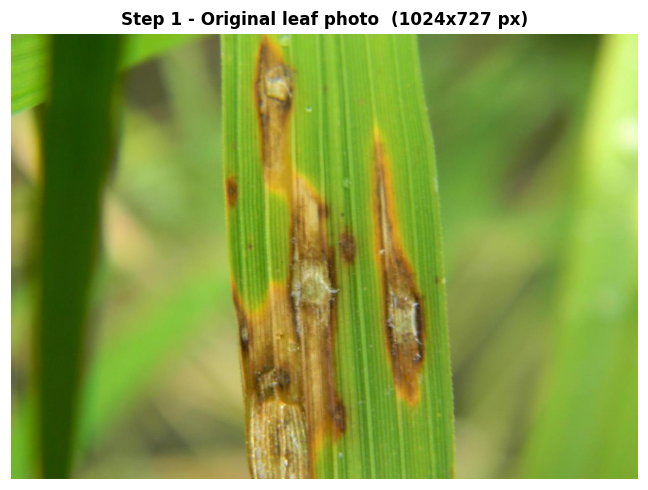

Loaded image  : blast_leaf.png
Resolution    : 1024 x 727 pixels
Channels      : 3 (R, G, B)
Pixel range   : 0-255  (mean brightness 111/255)


In [3]:
# === Step 1: load the original image =======================================
original_pil = Image.open(IMAGE_PATH).convert("RGB")
original = np.array(original_pil, dtype=np.uint8)

fig, ax = plt.subplots(figsize=(6, 4.5))
ax.imshow(original)
ax.set_title(f"Step 1 - Original leaf photo  ({original.shape[1]}x{original.shape[0]} px)")
ax.axis("off")
plt.tight_layout()
plt.show()

print(f"Loaded image  : {IMAGE_PATH.name}")
print(f"Resolution    : {original.shape[1]} x {original.shape[0]} pixels")
print(f"Channels      : {original.shape[2]} (R, G, B)")
print(f"Pixel range   : {original.min()}-{original.max()}  (mean brightness {original.mean():.0f}/255)")

## Step 2 — Preprocess to a canonical 128×128 image

Photos arrive at every size and brightness. The model needs a **fixed, comparable** input, so we:

1. **Letterbox-resize** to 128×128 — scale the leaf to fit and pad the rest with a neutral color, so the leaf is never stretched or distorted.
2. **Gently normalize brightness** — nudge the average leaf luminance toward a target so a dark or washed-out photo doesn't fool the color features.

The graph shows the photo *before* and *after*. From here on, all analysis runs on the 128×128 version.

C:\Users\Public\Documents\Wondershare\CreatorTemp\ipykernel_18624\3901517223.py:45: DeprecationWarning: LANCZOS is deprecated and will be removed in Pillow 10 (2023-07-01). Use Resampling.LANCZOS instead.
  resized = img.resize((nw, nh), Image.LANCZOS)


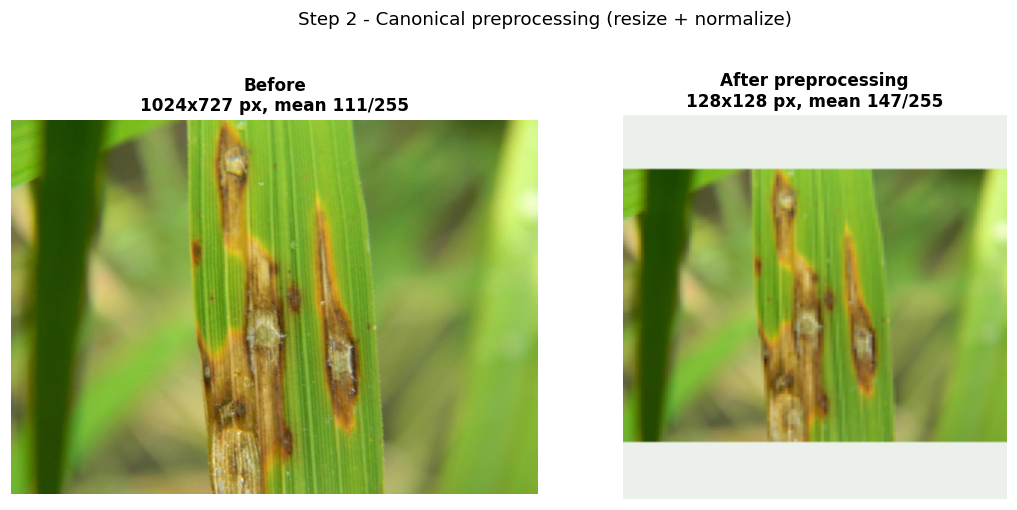

Resized to        : 128 x 128 (aspect preserved, padded)
Brightness before : 111.3/255
Brightness after  : 146.5/255
This 128x128 array `proc` is the input for every step that follows.


In [4]:
# === Step 2: preprocess (letterbox 128x128 + gentle brightness normalize) ===
_letterboxed = letterbox_resize(original_pil, IMG_SIZE, BG_COLOR)
_arr = np.array(_letterboxed, dtype=np.uint8)
_leaf_for_norm = plant_mask_from_rgb(_arr)
proc = gentle_luminance_normalize(_arr, _leaf_for_norm)
proc_pil = Image.fromarray(proc)

fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
axes[0].imshow(original)
axes[0].set_title(f"Before\n{original.shape[1]}x{original.shape[0]} px, mean {original.mean():.0f}/255")
axes[0].axis("off")
axes[1].imshow(proc)
axes[1].set_title(f"After preprocessing\n{IMG_SIZE}x{IMG_SIZE} px, mean {proc.mean():.0f}/255")
axes[1].axis("off")
fig.suptitle("Step 2 - Canonical preprocessing (resize + normalize)", y=1.02)
plt.tight_layout()
plt.show()

print(f"Resized to        : {IMG_SIZE} x {IMG_SIZE} (aspect preserved, padded)")
print(f"Brightness before : {original.mean():.1f}/255")
print(f"Brightness after  : {proc.mean():.1f}/255")
print("This 128x128 array `proc` is the input for every step that follows.")

## Step 3 — Look at the colors (RGB and HSV)

Blast lesions add **gray desaturated centers** (low S, mid V) and **brown margins** (hue toward red/orange). Watch the **Saturation** and **Hue** histograms — lesion pixels pull away from the healthy green peak.


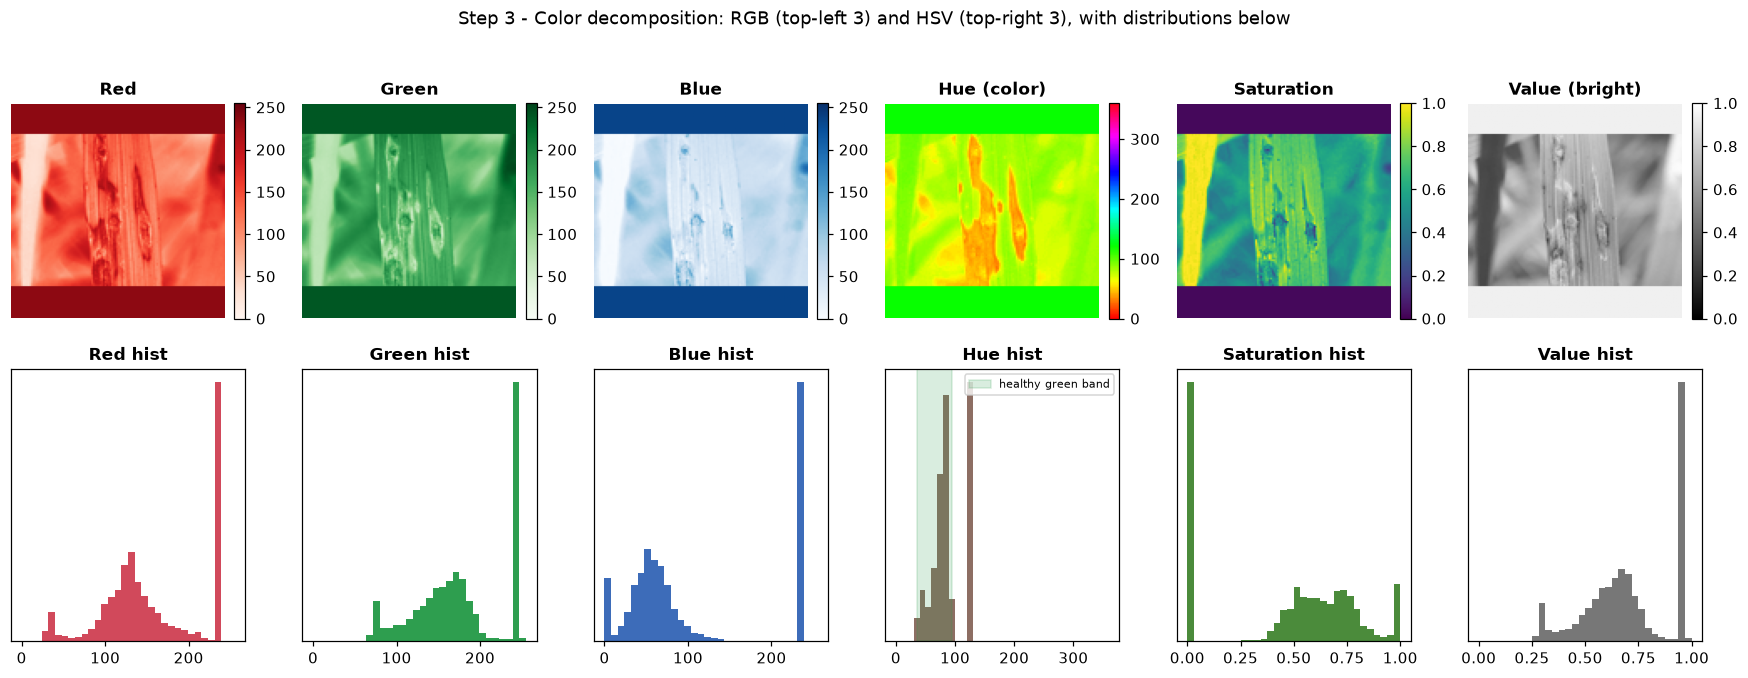

Share of pixels in the healthy-green hue band : 69.2%
Mean hue 74 deg | mean saturation 0.48 | mean value 0.70


In [5]:
# === Step 3: RGB and HSV channel maps + histograms =========================
hsv = rgb_to_hsv(proc)
H, S, V = hsv[..., 0], hsv[..., 1], hsv[..., 2]
Rc, Gc, Bc = proc[..., 0], proc[..., 1], proc[..., 2]

fig, axes = plt.subplots(2, 6, figsize=(16, 6))

# --- Top row: channel maps ---
maps = [
    ("Red",        Rc, "Reds",   (0, 255)),
    ("Green",      Gc, "Greens", (0, 255)),
    ("Blue",       Bc, "Blues",  (0, 255)),
    ("Hue (color)",H,  "hsv",    (0, 360)),
    ("Saturation", S,  "viridis",(0, 1)),
    ("Value (bright)", V, "gray",(0, 1)),
]
for ax, (name, chan, cmap, (lo, hi)) in zip(axes[0], maps):
    im = ax.imshow(chan, cmap=cmap, vmin=lo, vmax=hi)
    ax.set_title(name)
    ax.axis("off")
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

# --- Bottom row: histograms ---
axes[1, 0].hist(Rc.ravel(), bins=32, range=(0, 255), color="#d1495b"); axes[1, 0].set_title("Red hist")
axes[1, 1].hist(Gc.ravel(), bins=32, range=(0, 255), color="#2e9e4f"); axes[1, 1].set_title("Green hist")
axes[1, 2].hist(Bc.ravel(), bins=32, range=(0, 255), color="#3d6cb9"); axes[1, 2].set_title("Blue hist")
axes[1, 3].hist(H.ravel(), bins=36, range=(0, 360), color="#8d6e63")
axes[1, 3].axvspan(35, 95, color="#2e9e4f", alpha=0.18, label="healthy green band")
axes[1, 3].set_title("Hue hist"); axes[1, 3].legend(fontsize=7)
axes[1, 4].hist(S.ravel(), bins=32, range=(0, 1), color="#4b8b3b"); axes[1, 4].set_title("Saturation hist")
axes[1, 5].hist(V.ravel(), bins=32, range=(0, 1), color="#777777"); axes[1, 5].set_title("Value hist")
for ax in axes[1]:
    ax.set_yticks([])

fig.suptitle("Step 3 - Color decomposition: RGB (top-left 3) and HSV (top-right 3), with distributions below", y=1.02)
plt.tight_layout()
plt.show()

green_frac = float(((H >= 35) & (H <= 95) & (S >= 0.18)).mean())
print(f"Share of pixels in the healthy-green hue band : {green_frac*100:.1f}%")
print(f"Mean hue {H[S>0.1].mean():.0f} deg | mean saturation {S.mean():.2f} | mean value {V.mean():.2f}")

## Step 4 — Segment the Blast lesions

The mask marks off-green pixels inside the leaf: brown/yellow hues, dark necrotic tissue, and pale gray centers. On Blast leaves you should see **multiple elongated red patches** aligned with the leaf veins.


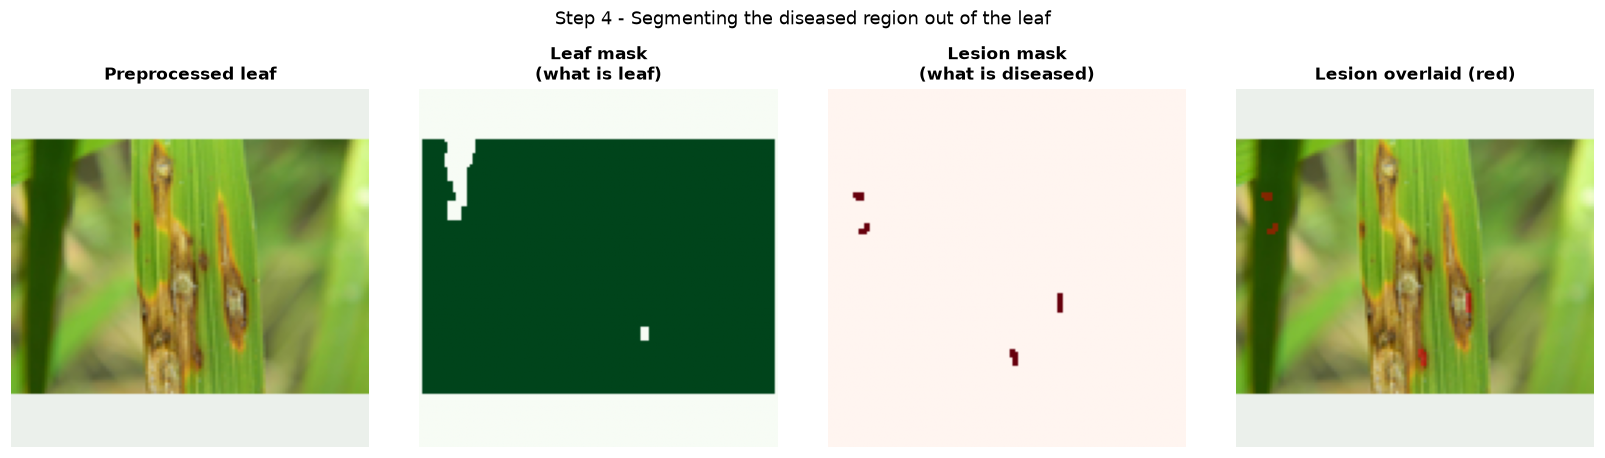

Leaf pixels     : 11,245
Lesion pixels   : 50
Lesion coverage : 0.4% of the leaf
Interpretation  : more coverage => more of the leaf is affected.


In [6]:
# === Step 4: lesion segmentation (leaf mask -> lesion mask, HSV rules) ======
MIN_LESION_PIXELS = 60


def _clean_mask(mask, open_it=1, close_it=2, min_size=8):
    """Morphological open+close, then drop tiny specks (scipy stand-in for skimage)."""
    m = ndi.binary_opening(mask, structure=np.ones((open_it + 1,) * 2))
    m = ndi.binary_closing(m, structure=np.ones((close_it + 1,) * 2))
    lbl, n = ndi.label(m)
    if n:
        sizes = ndi.sum(np.ones_like(lbl), lbl, index=np.arange(1, n + 1))
        keep = {i + 1 for i, s in enumerate(sizes) if s >= min_size}
        m = np.isin(lbl, list(keep)) if keep else np.zeros_like(m)
    return m.astype(bool)


def _otsu(values):
    """Otsu threshold on a 1-D array of values in [0,1]."""
    hist, edges = np.histogram(values, bins=64, range=(0, 1))
    hist = hist.astype(float)
    centers = (edges[:-1] + edges[1:]) / 2
    total = hist.sum()
    if total == 0:
        return 0.5
    w = np.cumsum(hist)
    mu = np.cumsum(hist * centers)
    muT = mu[-1]
    denom = w * (total - w)
    denom[denom == 0] = 1e-9
    between = (muT * w - mu) ** 2 / denom
    return float(centers[np.argmax(between)])


def segment_lesion(arr):
    """Return (lesion_mask, leaf_mask), faithful to lesion_features.segment_lesion."""
    leaf = _clean_mask(plant_mask_from_rgb(arr), min_size=32)
    if leaf.sum() < 64:
        leaf = np.ones(arr.shape[:2], dtype=bool)

    hsv_ = rgb_to_hsv(arr)
    h_, s_, v_ = hsv_[..., 0], hsv_[..., 1], hsv_[..., 2]
    brown_yellow = ((h_ < 35) | (h_ > 95)) & (s_ >= 0.25) & (v_ >= 0.15)
    dark_necrotic = (v_ < 0.28) & (s_ >= 0.18)
    pale_spot = (s_ < 0.15) & (v_ >= 0.65)
    gray_center = (s_ < 0.28) & (v_ >= 0.22) & (v_ <= 0.78)   # Blast gray-white necrotic centers
    hsv_lesion = leaf & (brown_yellow | dark_necrotic | pale_spot | gray_center)
    lesion = _clean_mask(hsv_lesion)

    if lesion.sum() >= MIN_LESION_PIXELS:
        return lesion, leaf

    # Otsu fallback: darker pixels inside the leaf.
    v_inside = v_[leaf]
    if v_inside.size >= 32 and (v_inside.max() - v_inside.min()) > 0.05:
        thr = _otsu(v_inside)
        otsu_mask = _clean_mask(leaf & (v_ < thr))
        if otsu_mask.sum() >= MIN_LESION_PIXELS:
            green_frac = float(((h_ >= 35) & (h_ <= 95) & (s_ >= 0.18) & leaf).sum() / max(leaf.sum(), 1))
            if otsu_mask.sum() / max(leaf.sum(), 1) > 0.80 and green_frac > 0.90:
                # Leaf is mostly healthy green with scattered spots — Otsu over-segmented.
                return _clean_mask(hsv_lesion), leaf
            return otsu_mask, leaf
    return _clean_mask(hsv_lesion), leaf


lesion_mask, leaf_mask = segment_lesion(proc)

# ---- Visualization: leaf mask, lesion mask, and overlay --------------------
overlay = proc.copy()
overlay[lesion_mask] = (0.55 * overlay[lesion_mask] + 0.45 * np.array([255, 0, 0])).astype(np.uint8)

fig, axes = plt.subplots(1, 4, figsize=(15, 4))
axes[0].imshow(proc); axes[0].set_title("Preprocessed leaf"); axes[0].axis("off")
axes[1].imshow(leaf_mask, cmap="Greens"); axes[1].set_title("Leaf mask\n(what is leaf)"); axes[1].axis("off")
axes[2].imshow(lesion_mask, cmap="Reds"); axes[2].set_title("Lesion mask\n(what is diseased)"); axes[2].axis("off")
axes[3].imshow(overlay); axes[3].set_title("Lesion overlaid (red)"); axes[3].axis("off")
fig.suptitle("Step 4 - Segmenting the diseased region out of the leaf", y=1.03)
plt.tight_layout()
plt.show()

leaf_px = int(leaf_mask.sum())
lesion_px = int(lesion_mask.sum())
coverage = lesion_px / max(leaf_px, 1)
print(f"Leaf pixels     : {leaf_px:,}")
print(f"Lesion pixels   : {lesion_px:,}")
print(f"Lesion coverage : {coverage*100:.1f}% of the leaf")
print("Interpretation  : more coverage => more of the leaf is affected.")

## Step 5 — Extract lesion features

Blast lesions are **spindle-shaped** — expect **high aspect ratio and eccentricity**, moderate grayness in HSV moments, and texture (GLCM) distinct from uniform healthy green.


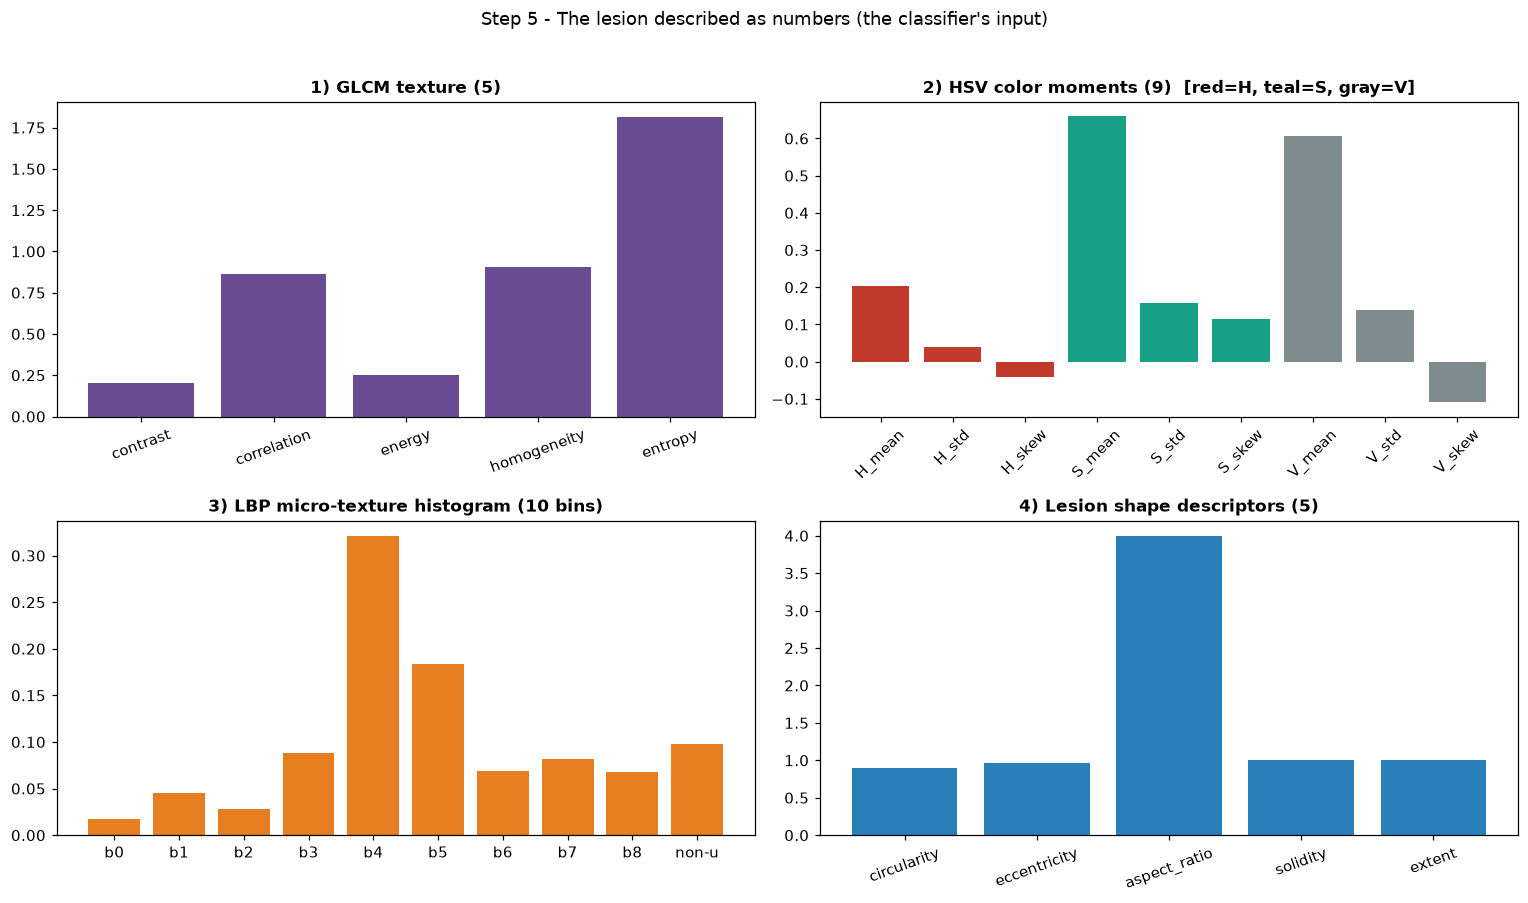

GLCM  : {'contrast': 0.202, 'correlation': 0.861, 'energy': 0.254, 'homogeneity': 0.906, 'entropy': 1.814}
Shape : {'circularity': 0.898, 'eccentricity': 0.968, 'aspect_ratio': 4.0, 'solidity': 1.0, 'extent': 1.0, 'n_blobs': 4}
Lesion blobs detected: 4


In [7]:
# === Step 5: feature extraction (GLCM, HSV moments, LBP, shape) ============
GLCM_LEVELS = 8


def glcm_features(gray, mask):
    """5 Haralick features on lesion pixels: contrast, correlation, energy, homogeneity, entropy."""
    if not mask.any():
        return dict(contrast=0, correlation=0, energy=0, homogeneity=0, entropy=0)
    q = np.clip((gray.astype(int) * (GLCM_LEVELS - 1)) // 255 + 1, 1, GLCM_LEVELS - 1)
    qm = np.where(mask, q, 0)
    Hh, Ww = qm.shape
    P = np.zeros((GLCM_LEVELS, GLCM_LEVELS), dtype=float)
    for dy, dx in [(0, 1), (-1, 1), (-1, 0), (-1, -1)]:   # 4 angles, distance 1
        ys_s = slice(max(0, -dy), Hh - max(0, dy)); xs_s = slice(max(0, -dx), Ww - max(0, dx))
        ys_d = slice(max(0, dy), Hh - max(0, -dy)); xs_d = slice(max(0, dx), Ww - max(0, -dx))
        a = qm[ys_s, xs_s].ravel(); b = qm[ys_d, xs_d].ravel()
        ok = (a > 0) & (b > 0)
        np.add.at(P, (a[ok], b[ok]), 1)
        np.add.at(P, (b[ok], a[ok]), 1)            # symmetric
    P = P[1:, 1:]
    if P.sum() == 0:
        return dict(contrast=0, correlation=0, energy=0, homogeneity=0, entropy=0)
    p = P / P.sum()
    L = p.shape[0]
    i = np.arange(L)[:, None]; j = np.arange(L)[None, :]
    contrast = float(((i - j) ** 2 * p).sum())
    energy = float((p ** 2).sum())
    homogeneity = float((p / (1.0 + np.abs(i - j))).sum())
    entropy = float(-(p[p > 0] * np.log(p[p > 0])).sum())
    px = p.sum(1); py = p.sum(0); lv = np.arange(L)
    mu_i = (lv * px).sum(); mu_j = (lv * py).sum()
    sig_i = np.sqrt(((lv - mu_i) ** 2 * px).sum()); sig_j = np.sqrt(((lv - mu_j) ** 2 * py).sum())
    cov = ((i - mu_i) * (j - mu_j) * p).sum()
    correlation = float(cov / (sig_i * sig_j)) if sig_i > 1e-9 and sig_j > 1e-9 else 0.0
    return dict(contrast=contrast, correlation=correlation, energy=energy,
                homogeneity=homogeneity, entropy=entropy)


def hsv_moments(arr, mask):
    """mean/std/skew for H, S, V on lesion pixels (9 numbers). Hue scaled to [0,1]."""
    hsv_ = rgb_to_hsv(arr).astype(np.float64)
    hsv_[..., 0] /= 360.0
    out = {}
    for c, name in enumerate("HSV"):
        ch = hsv_[..., c][mask]
        if ch.size == 0:
            out[f"{name}_mean"], out[f"{name}_std"], out[f"{name}_skew"] = 0.0, 0.0, 0.0
            continue
        mu = float(ch.mean()); sd = float(np.sqrt(((ch - mu) ** 2).mean()))
        m3 = float(((ch - mu) ** 3).mean())
        out[f"{name}_mean"], out[f"{name}_std"] = mu, sd
        out[f"{name}_skew"] = float(np.sign(m3) * np.cbrt(abs(m3)))
    return out


def lbp_histogram(gray, mask):
    """Uniform LBP (P=8, R=1) -> 10-bin normalized histogram on lesion pixels."""
    g = gray.astype(np.float32)
    offs = [(0, 1), (-1, 1), (-1, 0), (-1, -1), (0, -1), (1, -1), (1, 0), (1, 1)]
    bits = np.stack([(np.roll(np.roll(g, -dy, 0), -dx, 1) >= g) for dy, dx in offs], axis=0)
    ones = bits.sum(0)
    transitions = (bits ^ np.roll(bits, -1, axis=0)).sum(0)     # bool XOR = pattern changes
    code = np.where(transitions <= 2, ones, 9).astype(int)      # 0..8 uniform, 9 = non-uniform
    vals = code[mask]
    hist = np.bincount(vals, minlength=10)[:10].astype(float)
    return hist / hist.sum() if hist.sum() > 0 else hist


def shape_features(mask):
    """Geometry of the largest lesion blob: circularity, eccentricity, aspect, solidity, extent."""
    z = dict(circularity=0, eccentricity=0, aspect_ratio=0, solidity=0, extent=0, n_blobs=0)
    if not mask.any():
        return z
    lbl, n = ndi.label(mask)
    z["n_blobs"] = int(n)
    if n == 0:
        return z
    sizes = ndi.sum(np.ones_like(lbl), lbl, index=np.arange(1, n + 1))
    big = int(np.argmax(sizes)) + 1
    blob = lbl == big
    area = float(blob.sum())
    boundary = blob & ~ndi.binary_erosion(blob)
    perim = float(boundary.sum())
    circularity = float(4 * np.pi * area / (perim ** 2)) if perim > 0 else 0.0
    ys, xs = np.where(blob)
    cy, cx = ys.mean(), xs.mean()
    cov = np.cov(np.stack([ys - cy, xs - cx]))
    eig = np.sort(np.linalg.eigvalsh(cov))[::-1] if cov.shape == (2, 2) else np.array([1.0, 1.0])
    eig = np.clip(eig, 1e-9, None)
    major, minor = 4 * np.sqrt(eig[0]), 4 * np.sqrt(eig[1])
    eccentricity = float(np.sqrt(max(0.0, 1 - (minor ** 2) / (major ** 2))))
    aspect_ratio = float(major / minor) if minor > 1e-6 else 0.0
    minr, maxr, minc, maxc = ys.min(), ys.max(), xs.min(), xs.max()
    bbox_area = float((maxr - minr + 1) * (maxc - minc + 1))
    extent = float(area / bbox_area) if bbox_area > 0 else 0.0
    solidity = 0.0
    try:
        from scipy.spatial import ConvexHull
        pts = np.stack([xs, ys], axis=1)
        if len(pts) >= 3:
            solidity = float(area / ConvexHull(pts).volume)
    except Exception:
        solidity = float(extent)
    return dict(circularity=min(circularity, 1.0), eccentricity=eccentricity,
                aspect_ratio=aspect_ratio, solidity=min(solidity, 1.0),
                extent=extent, n_blobs=int(n))


# ---- Compute on the segmented lesion (or whole leaf if no lesion) ----------
gray = proc.mean(axis=2).astype(np.uint8)
stat_mask = lesion_mask if lesion_mask.sum() >= MIN_LESION_PIXELS else leaf_mask

glcm = glcm_features(gray, stat_mask)
hmom = hsv_moments(proc, stat_mask)
lbp = lbp_histogram(gray, stat_mask)
shape = shape_features(lesion_mask)

# ---- Plot the four feature groups -----------------------------------------
fig, axes = plt.subplots(2, 2, figsize=(14, 8))

axes[0, 0].bar(list(glcm.keys()), list(glcm.values()), color="#6a4c93")
axes[0, 0].set_title("1) GLCM texture (5)"); axes[0, 0].tick_params(axis="x", rotation=20)

hk = list(hmom.keys()); hv = list(hmom.values())
hc = ["#c0392b" if k[0] == "H" else "#16a085" if k[0] == "S" else "#7f8c8d" for k in hk]
axes[0, 1].bar(hk, hv, color=hc)
axes[0, 1].set_title("2) HSV color moments (9)  [red=H, teal=S, gray=V]")
axes[0, 1].tick_params(axis="x", rotation=45)

axes[1, 0].bar([f"b{i}" if i < 9 else "non-u" for i in range(10)], lbp, color="#e67e22")
axes[1, 0].set_title("3) LBP micro-texture histogram (10 bins)")

sk = ["circularity", "eccentricity", "aspect_ratio", "solidity", "extent"]
axes[1, 1].bar(sk, [shape[k] for k in sk], color="#2980b9")
axes[1, 1].set_title("4) Lesion shape descriptors (5)"); axes[1, 1].tick_params(axis="x", rotation=20)

fig.suptitle("Step 5 - The lesion described as numbers (the classifier's input)", y=1.02)
plt.tight_layout()
plt.show()

print("GLCM  :", {k: round(v, 3) for k, v in glcm.items()})
print("Shape :", {k: round(v, 3) for k, v in shape.items()})
print(f"Lesion blobs detected: {shape['n_blobs']}")

## Step 6 — Score the diseases (expect BLAST to win)

The scorer boosts **blast** when it sees gray lesion centers plus elongated shape (high aspect ratio / eccentricity). **Brown spot** needs rounder lesions; **bacterial blight** needs long pale streaks.


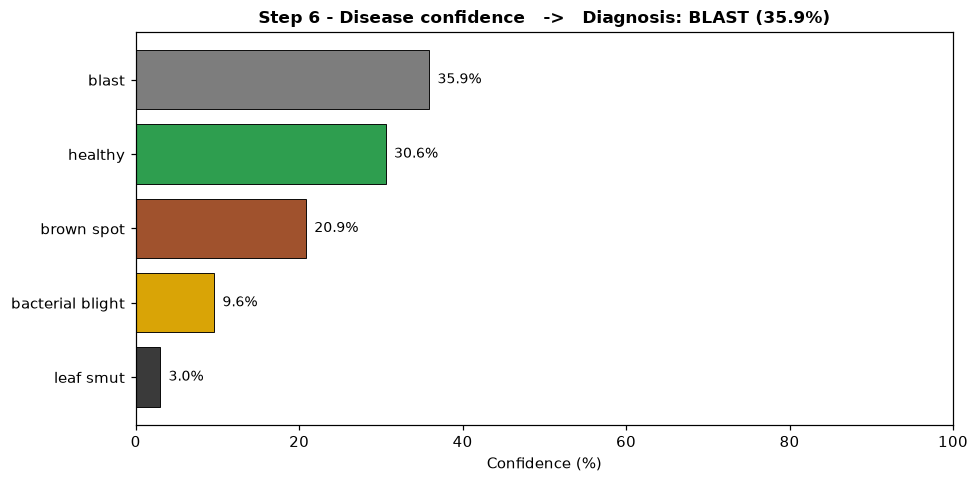

Signals read from lesion:
  coverage=0.4%  brownness=0.09  yellowness=0.21  grayness=0.00  paleness=0.00  darkness=0.04
  circularity=0.90  aspect_ratio=4.00  eccentricity=0.97  blobs=4

Ranked confidence:
  blast               35.9%
  healthy             30.6%
  brown spot          20.9%
  bacterial blight     9.6%
  leaf smut            3.0%


In [8]:
# === Step 6: simulated disease scoring =====================================

def clamp(x):

    return float(max(0.0, min(1.0, x)))





# ---- Read human-readable signals from the lesion pixels --------------------

lh, ls, lv = H[stat_mask], S[stat_mask], V[stat_mask]

n_les = max(lh.size, 1)

brownness = float((((lh >= 8) & (lh <= 45)) & (ls >= 0.25)).mean())      # brown/orange, saturated

yellowness = float((((lh > 45) & (lh <= 70)) & (ls >= 0.2)).mean())       # yellow

grayness = float(((ls < 0.28) & (lv >= 0.22) & (lv <= 0.78)).mean())        # gray necrotic centre

paleness = float(((ls < 0.15) & (lv >= 0.65)).mean())                      # washed-out

darkness = float((lv < 0.3).mean())                                        # dark necrotic



circ = shape["circularity"]

aspect = shape["aspect_ratio"]

ecc = shape["eccentricity"]

nb = shape["n_blobs"]

mean_blob_frac = (lesion_px / max(nb, 1)) / max(leaf_px, 1)                 # avg blob size vs leaf



# ---- Disease fingerprints -> raw scores ------------------------------------

# Each line encodes what that disease looks like. `many_specks` gates leaf smut

# so a few round spots don't get misread as smut.

many_specks = clamp((nb - 12) / 20.0)

scores = {

    # almost no lesion -> healthy

    "healthy":          3.0 * clamp((0.04 - coverage) / 0.04),

    # round-oval BROWN lesions, not elongated, no gray centre

    "brown spot":       3.0 * brownness + 1.6 * circ + 0.8 * clamp(coverage / 0.15)

                        + 0.8 * clamp(1 - (aspect - 1) / 2.5) + 0.5 * (1 - grayness),

    # spindle/diamond lesions with GRAY centres (needs gray to score)

    "blast":            2.4 * grayness + 1.4 * clamp((aspect - 1.5) / 1.5) + 1.2 * ecc

                        + 0.9 * brownness + 0.8 * yellowness

                        + 1.0 * clamp(coverage / 0.12),

    # long PALE/yellow streaks along the leaf (very elongated)

    "bacterial blight": 2.0 * (paleness + yellowness) + 1.8 * clamp((aspect - 3.0) / 2.0)

                        + 0.8 * clamp(coverage / 0.25),

    # MANY tiny dark specks scattered over the leaf

    "leaf smut":        2.6 * many_specks + 1.2 * darkness * many_specks,

    # broad yellow-orange discoloration over a large area

}



# ---- Softmax -> probabilities ----------------------------------------------

labels = list(scores.keys())

raw = np.array([scores[k] for k in labels], dtype=float)

exp = np.exp((raw - raw.max()) / 1.15)

probs = exp / exp.sum()

prob_map = dict(sorted(zip(labels, probs), key=lambda kv: -kv[1]))



diagnosis = next(iter(prob_map))

confidence = prob_map[diagnosis]



# ---- Confidence bar chart --------------------------------------------------

order = list(prob_map.keys())

vals = [prob_map[k] * 100 for k in order]

colors = [CLASS_COLORS[k] for k in order]



fig, ax = plt.subplots(figsize=(9, 4.5))

bars = ax.barh(order[::-1], vals[::-1], color=colors[::-1], edgecolor="black", linewidth=0.6)

for bar, v in zip(bars, vals[::-1]):

    ax.text(v + 1, bar.get_y() + bar.get_height() / 2, f"{v:.1f}%", va="center", fontsize=9)

ax.set_xlim(0, 100)

ax.set_xlabel("Confidence (%)")

ax.set_title(f"Step 6 - Disease confidence   ->   Diagnosis: {diagnosis.upper()} ({confidence*100:.1f}%)")

plt.tight_layout()

plt.show()



print("Signals read from lesion:")

print(f"  coverage={coverage*100:.1f}%  brownness={brownness:.2f}  yellowness={yellowness:.2f}"

      f"  grayness={grayness:.2f}  paleness={paleness:.2f}  darkness={darkness:.2f}")

print(f"  circularity={circ:.2f}  aspect_ratio={aspect:.2f}  eccentricity={ecc:.2f}  blobs={nb}")

print("\nRanked confidence:")

for k, v in prob_map.items():

    print(f"  {k:<18} {v*100:5.1f}%")


## Step 7 — The whole process on one picture

This flow diagram ties the steps together: the photo flows left-to-right through preprocessing, lesion segmentation, feature extraction, and classification, ending in the diagnosis. It's the "map" of everything above.

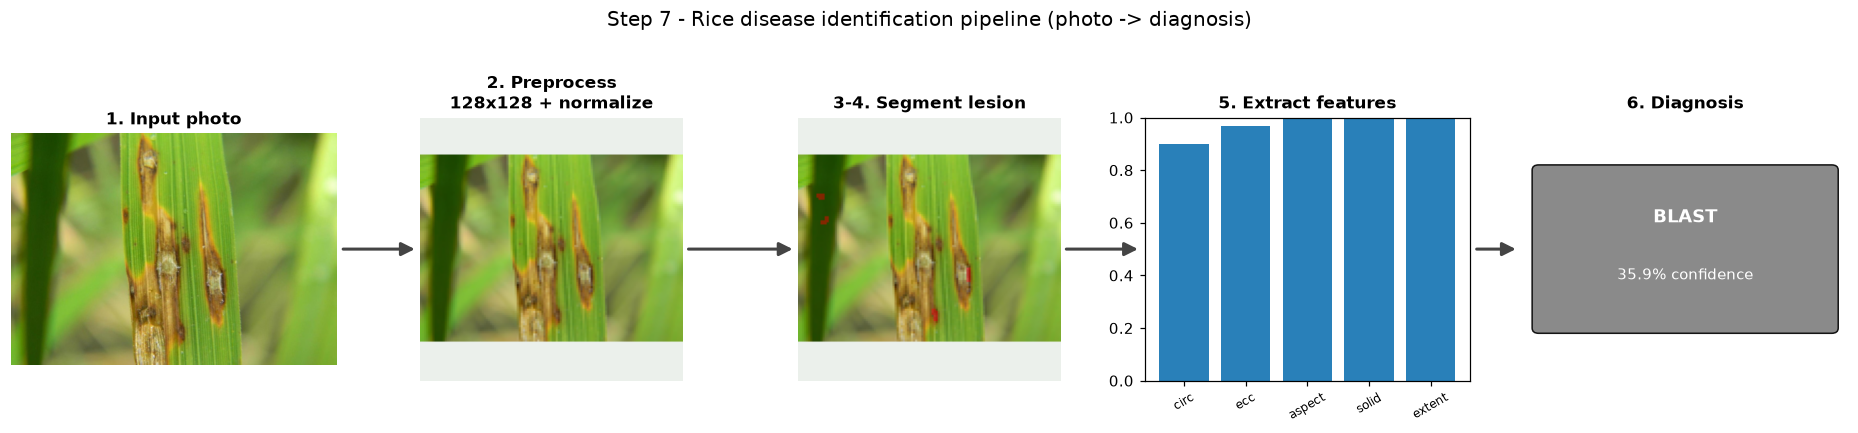

In [9]:
# === Step 7: pipeline flow diagram =========================================
from matplotlib.patches import ConnectionPatch

fig, axes = plt.subplots(1, 5, figsize=(17, 3.6))

# Panel 1: original
axes[0].imshow(original); axes[0].set_title("1. Input photo")

# Panel 2: preprocessed
axes[1].imshow(proc); axes[1].set_title("2. Preprocess\n128x128 + normalize")

# Panel 3: lesion overlay
axes[2].imshow(overlay); axes[2].set_title("3-4. Segment lesion")

# Panel 4: feature snapshot (shape descriptors)
sk = ["circ", "ecc", "aspect", "solid", "extent"]
sv = [shape["circularity"], shape["eccentricity"], min(shape["aspect_ratio"], 4) / 4,
      shape["solidity"], shape["extent"]]
axes[3].bar(sk, sv, color="#2980b9"); axes[3].set_ylim(0, 1)
axes[3].set_title("5. Extract features"); axes[3].tick_params(axis="x", rotation=30, labelsize=8)

# Panel 5: diagnosis card
axes[4].axis("off")
axes[4].add_patch(patches.FancyBboxPatch(
    (0.05, 0.2), 0.9, 0.6, boxstyle="round,pad=0.02",
    facecolor=CLASS_COLORS[diagnosis], edgecolor="black", alpha=0.9,
    transform=axes[4].transAxes))
axes[4].text(0.5, 0.62, diagnosis.upper(), ha="center", va="center", color="white",
             fontsize=12, fontweight="bold", transform=axes[4].transAxes)
axes[4].text(0.5, 0.40, f"{confidence*100:.1f}% confidence", ha="center", va="center",
             color="white", fontsize=10, transform=axes[4].transAxes)
axes[4].set_title("6. Diagnosis")

for ax in axes[:3]:
    ax.axis("off")

# Arrows between panels
for i in range(4):
    con = ConnectionPatch(xyA=(1.02, 0.5), coordsA=axes[i].transAxes,
                          xyB=(-0.02, 0.5), coordsB=axes[i + 1].transAxes,
                          arrowstyle="-|>", mutation_scale=18, lw=2, color="#444")
    fig.add_artist(con)

fig.suptitle("Step 7 - Rice disease identification pipeline (photo -> diagnosis)", y=1.08, fontsize=13)
plt.tight_layout()
plt.show()

## Step 8 — Final diagnosis dashboard

Expected result: **BLAST** with PhilRice-aligned management steps (reduce nitrogen, scout at tillering/booting, fungicide at heading).


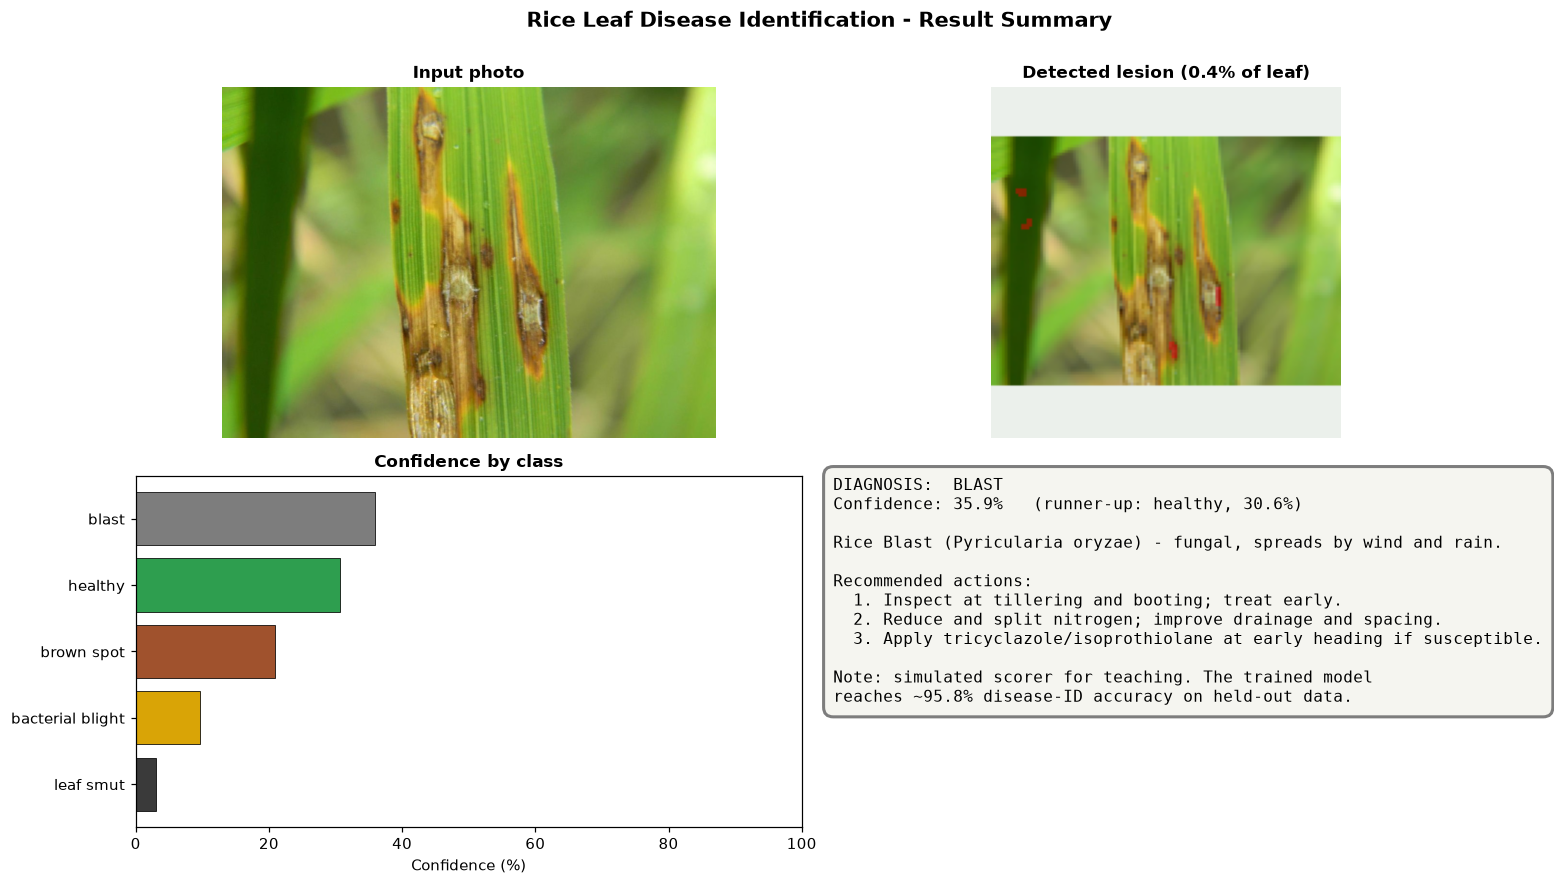

FINAL DIAGNOSIS : BLAST  (35.9% confidence)
Lesion coverage : 0.4% of the leaf


In [10]:
# === Step 8: final diagnosis dashboard =====================================



# Condensed PhilRice-aligned guidance (from detection/disease_guide.py).



RECOMMENDATIONS = {



    "healthy": (



        "Leaf looks healthy - no pathogen detected.",



        ["Keep proper water depth and drainage for the growth stage.",



         "Fertilise from soil test / PhilRice Nutrient Manager.",



         "Scout twice a week for early BLB and blast signs."]),



    "brown spot": (



        "Brown Spot (Bipolaris oryzae) - fungal, often tied to poor soil fertility or stress.",



        ["Confirm round/oval lesions with gray-tan centres (vs diamond-shaped blast).",



         "Correct fertility: balanced NPK, fix potassium/silicon if low.",



         "Keep even irrigation; spray mancozeb/propiconazole if it spreads."]),



    "blast": (



        "Rice Blast (Pyricularia oryzae) - fungal, spreads by wind and rain.",



        ["Inspect at tillering and booting; treat early.",



         "Reduce and split nitrogen; improve drainage and spacing.",



         "Apply tricyclazole/isoprothiolane at early heading if susceptible."]),



    "bacterial blight": (



        "Bacterial Leaf Blight (Xanthomonas oryzae) - bacterial, worse in the rainy season.",



        ["Drain the field briefly after heavy rain; avoid deep flooding.",



         "Split nitrogen; remove and bury heavily infected plants.",



         "Next crop: use BLB-resistant certified seed - chemicals rarely economical."]),



    "leaf smut": (



        "Leaf Smut (Entyloma oryzae) - usually minor; seed-borne dark leaf specks.",



        ["Use certified disease-free seed next planting.",



         "Hot-water or approved seed treatment before sowing.",



         "Avoid excess nitrogen; remove heavily infected leaves."]),



}







summary, steps = RECOMMENDATIONS[diagnosis]



runner_up = list(prob_map.keys())[1]







fig = plt.figure(figsize=(15, 8))



gs = fig.add_gridspec(2, 2, height_ratios=[1, 1])







ax1 = fig.add_subplot(gs[0, 0]); ax1.imshow(original); ax1.axis("off")



ax1.set_title("Input photo")







ax2 = fig.add_subplot(gs[0, 1]); ax2.imshow(overlay); ax2.axis("off")



ax2.set_title(f"Detected lesion ({coverage*100:.1f}% of leaf)")







ax3 = fig.add_subplot(gs[1, 0])



order = list(prob_map.keys())



vals = [prob_map[k] * 100 for k in order]



ax3.barh(order[::-1], vals[::-1], color=[CLASS_COLORS[k] for k in order][::-1],



         edgecolor="black", linewidth=0.5)



ax3.set_xlim(0, 100); ax3.set_xlabel("Confidence (%)"); ax3.set_title("Confidence by class")







ax4 = fig.add_subplot(gs[1, 1]); ax4.axis("off")



lines = [f"DIAGNOSIS:  {diagnosis.upper()}",



         f"Confidence: {confidence*100:.1f}%   (runner-up: {runner_up}, {prob_map[runner_up]*100:.1f}%)",



         "",



         summary,



         "",



         "Recommended actions:"]



lines += [f"  {i}. {s}" for i, s in enumerate(steps, 1)]



lines += ["", "Note: simulated scorer for teaching. The trained model", "reaches ~95.8% disease-ID accuracy on held-out data."]



ax4.text(0.0, 1.0, "\n".join(lines), va="top", ha="left", fontsize=10.5, family="monospace",



         bbox=dict(boxstyle="round,pad=0.6", facecolor="#f5f5f0", edgecolor=CLASS_COLORS[diagnosis], lw=2))







fig.suptitle("Rice Leaf Disease Identification - Result Summary", y=1.0, fontsize=14, fontweight="bold")



plt.tight_layout()



plt.show()







print("=" * 60)



print(f"FINAL DIAGNOSIS : {diagnosis.upper()}  ({confidence*100:.1f}% confidence)")



print(f"Lesion coverage : {coverage*100:.1f}% of the leaf")



print("=" * 60)



## Side-by-side comparison (Blast vs healthy vs brown spot)

Compare lesion coverage across the three sample notebooks.


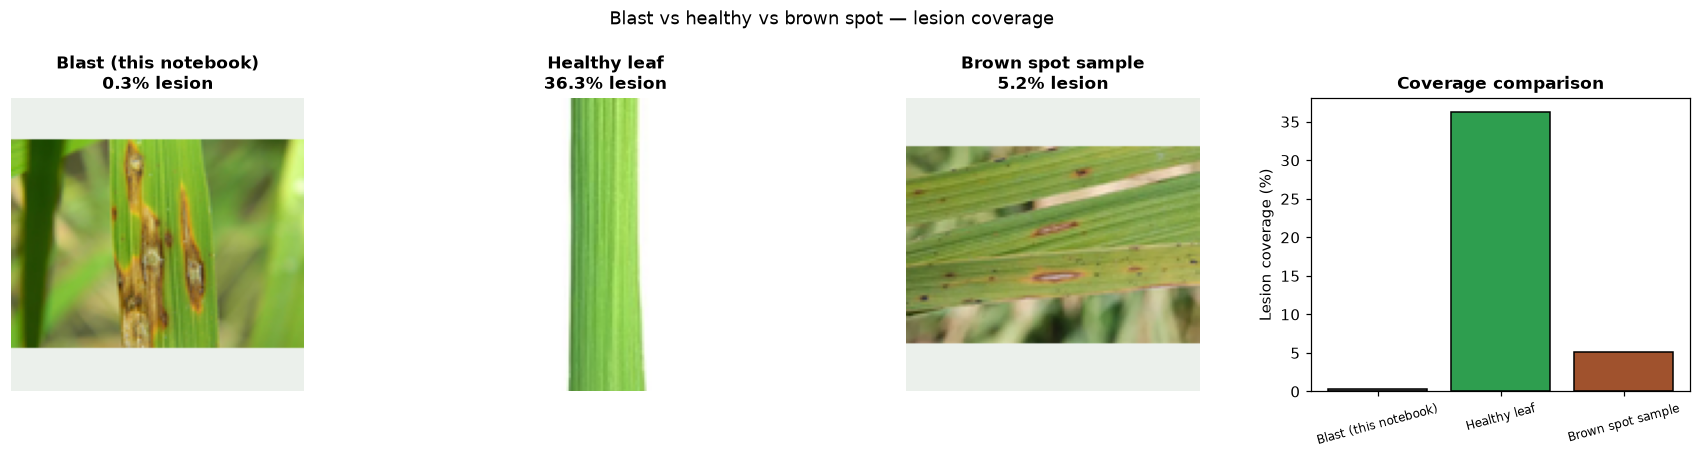

This notebook diagnosis: BLAST (35.9%)


In [11]:
# === Bonus: compare Blast vs healthy vs brown-spot samples =================
samples = [
    ("Blast (this notebook)", Path("assets/blast_leaf.png"), CLASS_COLORS["blast"]),
    ("Healthy leaf", Path("assets/healthy_leaf.jpg"), CLASS_COLORS["healthy"]),
    ("Brown spot sample", Path("assets/sample_leaf.png"), CLASS_COLORS["brown spot"]),
]
rows = []
for label, path, color in samples:
    if not path.exists():
        path = Path("notebooks") / path
    if not path.exists():
        continue
    pil = Image.open(path).convert("RGB")
    arr = np.array(letterbox_resize(pil, IMG_SIZE, BG_COLOR))
    les, lf = segment_lesion(arr)
    cov = les.sum() / max(lf.sum(), 1)
    rows.append((label, arr, cov, color))

if rows:
    fig, axes = plt.subplots(1, len(rows) + 1, figsize=(4 * (len(rows) + 1), 4))
    for ax, (label, arr, cov, color) in zip(axes[:-1], rows):
        ax.imshow(arr); ax.set_title(f"{label}\n{cov*100:.1f}% lesion"); ax.axis("off")
    axes[-1].bar([r[0] for r in rows], [r[2]*100 for r in rows],
                   color=[r[3] for r in rows], edgecolor="black")
    axes[-1].set_ylabel("Lesion coverage (%)"); axes[-1].set_title("Coverage comparison")
    axes[-1].tick_params(axis="x", rotation=15, labelsize=8)
    fig.suptitle("Blast vs healthy vs brown spot — lesion coverage", y=1.03)
    plt.tight_layout(); plt.show()
    print(f"This notebook diagnosis: {diagnosis.upper()} ({confidence*100:.1f}%)")
else:
    print("Comparison images not found in assets/.")
